<a href="https://colab.research.google.com/github/limzhilit/ml-campus_data_project-colab/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import CSV and libraries

In [204]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [205]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import data_table

In [206]:
df = pd.read_csv(
    '/content/drive/MyDrive/ML_lab/CampusWalkDataset_TemplateIDs.csv',
    skiprows=4,
    keep_default_na=False # to avoid loading None in as null
)



Setup the table library from Google Colab to show data more clearly


In [207]:
# Increase maximum displayed columns
data_table.DataTable.max_columns = 30

# DataFrame display settings
data_table.enable_dataframe_formatter()

Delete (empty/with only id row) and (col)

In [208]:
# Convert empty strings and whitespace-only cells into NaN
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Remove completely empty columns
df = df.dropna(axis=1, how='all')

# Remove observations where all columns except recorder_id are empty
df = df.dropna(
    subset=df.columns.drop("recorder_id"),
    how="all"
)

# Reset row numbering
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Dataset shape: (135, 23)
Exact duplicate rows: 0


In [209]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   recorder_id                            135 non-null    object
 1   date                                   135 non-null    object
 2   location                               135 non-null    object
 3   weather                                135 non-null    object
 4   temperature_c                          135 non-null    object
 5   sound level                            135 non-null    object
 6   foot_traffic                           135 non-null    object
 7   primary_sound_type_urban               135 non-null    object
 8   other_sound_type_urban                 132 non-null    object
 9   primary_sound_type_nature              135 non-null    object
 10  other_sound_type_nature                133 non-null    object
 1

Use heatmap to spot missing value instantly

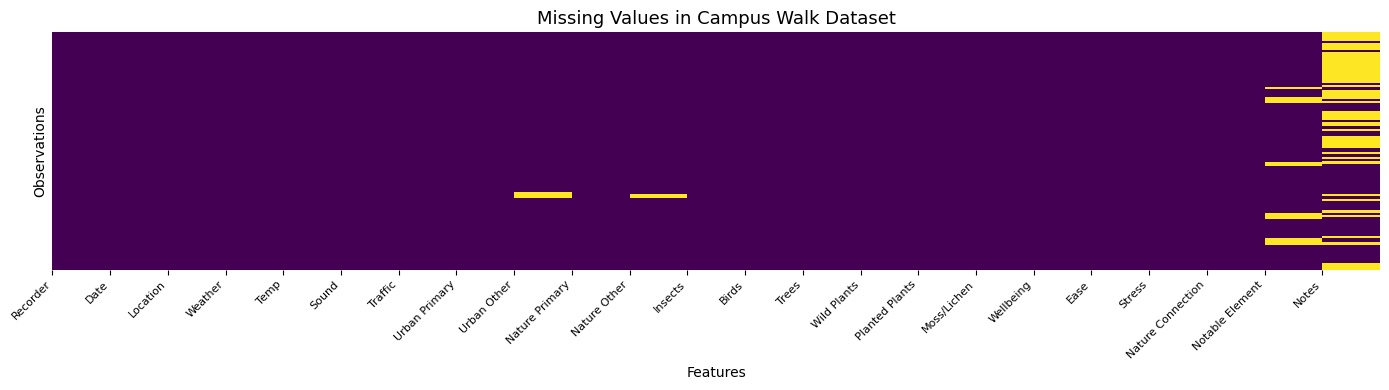

In [210]:
# @title
plt.figure(figsize=(14, 4))

ax = sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

short_labels = [
    "Recorder", "Date", "Location", "Weather", "Temp",
    "Sound", "Traffic", "Urban Primary", "Urban Other",
    "Nature Primary", "Nature Other", "Insects", "Birds",
    "Trees", "Wild Plants", "Planted Plants", "Moss/Lichen",
    "Wellbeing", "Ease", "Stress", "Nature Connection",
    "Notable Element", "Notes"
]

ax.set_xticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=45, ha="right", fontsize=8)

plt.title("Missing Values in Campus Walk Dataset", fontsize=13)
plt.xlabel("Features")
plt.ylabel("Observations")

plt.tight_layout()
plt.show()

Count of missing cells

In [211]:
# @title
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage
other_notes,65,48.15
most_notable_nature_element,13,9.63
other_sound_type_urban,3,2.22
other_sound_type_nature,2,1.48


Convert numeric cols to numeric data type

In [212]:
numerical_columns = [
    "temperature_c",
    "insects_count",
    "birds_count"
]

# Check numerical data quality
for col in numerical_columns:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Unique values:", sorted(df[col].dropna().unique()))


temperature_c
Data type: object
Missing values: 0
Minimum: 10
Maximum: 19C
Unique values: ['10', '13', '14', '15', '16', '16.5', '16C', '17', '17C', '18', '18C', '19', '19C']

insects_count
Data type: object
Missing values: 0
Minimum: 0
Maximum: 7
Unique values: ['0', '1', '10', '2', '20', '25', '26', '3', '31', '4', '5', '6', '7']

birds_count
Data type: object
Missing values: 0
Minimum: 0
Maximum: 6
Unique values: ['0', '1', '10', '12', '13', '2', '20', '3', '4', '5', '6']


Remove celcius unit from data, validate data range and convert to float

In [213]:
# Remove Celsius units and whitespace
df["temperature_c"] = (
    df["temperature_c"]
    .astype("string")
    .str.replace(r"[°Cc\s]", "", regex=True)
)

# Convert to numeric
df["temperature_c"] = pd.to_numeric(
    df["temperature_c"],
    errors="coerce"
)

# Define acceptable temperature range
MIN_TEMP = -5
MAX_TEMP = 40

# Identify potentially unrealistic temperatures
invalid_temp = df[
    (df["temperature_c"] < MIN_TEMP) |
    (df["temperature_c"] > MAX_TEMP)
]

display(invalid_temp[["recorder_id", "date", "location", "temperature_c"]])

,recorder_id,date,location,temperature_c


Convert insect and bird count to int




In [214]:
# @title
# Convert count columns to numeric
count_columns = ["insects_count", "birds_count"]

for col in count_columns:
    df[col] = pd.to_numeric(df[col])

# Verify data types
display(df[count_columns].dtypes.to_frame("Data Type"))

,Data Type
insects_count,int64
birds_count,int64


Categories data

In [215]:
# Environmental characteristics used for clustering
clustering_features = [
    "weather",
    "temperature_c",
    "sound level",
    "foot_traffic",
    "primary_sound_type_urban",
    "other_sound_type_urban",
    "primary_sound_type_nature",
    "other_sound_type_nature",
    "insects_count",
    "birds_count",
    "trees_presence",
    "native_or_wild_plant_presence",
    "ornnamental_or_planted_plant_presence",
    "moss_or_lichen_presence"
]

# Human-experience variables used to evaluate the clusters
outcome_features = [
    "wellbeing_rating",
    "ease_rating",
    "stress_rating",
    "nature_connection_experience_rating"
]

In [216]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].dropna().unique())


recorder_id
['R26_001' 'R26_002' 'R26_003' 'R26_004' 'R26_005' 'R26_006' 'R26_007'
 'R26_008' 'R26_009' 'R26_010' 'R26_011' 'R26_012' 'R26_013' 'R26_014'
 'R26_015' 'R26_016' 'R26_017' 'R26_018' 'R26_019' 'R26_020' 'R26_021'
 'R26_022' 'R26_023' 'R26_024' 'R26_025' 'R26_026' 'R26_027' 'R26_028']

date
['22/09/2026' '23/09/2026' '24/09/2026' '25/09/2026' '26/09/2026'
 '27/09/2026' '28/09/2026' '07/10/2026']

location
['L01 MainEntrance' 'L02 LibraryGreen' 'L06 HedgingBehindSportsCentre'
 'L08 AccessRoadNearSportsCentre' 'L04 PathFrontiHub'
 'L05 GreenFrontSportsCentre' 'L07 CarParkNearSportsCentre'
 'L03 LowerSidePathiHub' 'L10 OtherOffCampus']

weather
['Partly cloudy' 'Sunny' 'Windy' 'Cloudy' 'sunny']

sound level
['Quiet' 'Moderate' 'Loud']

foot_traffic
['Low' 'Moderate' 'High' 'low']

primary_sound_type_urban
['Human voices' 'Traffic' 'Construction' 'Service machinery' 'Other']

other_sound_type_urban
['Traffic' 'Human voices' 'Other' 'Service machinery' 'Construction']

primary_s

In [217]:
# @title Data info

# Combine environmental and outcome variables
selected_features = clustering_features + outcome_features

# Inspect data types and missing values
quality_check = pd.DataFrame({
    "Data Type": df[selected_features].dtypes,
    "Missing Values": df[selected_features].isnull().sum(),
    "Unique Values": df[selected_features].nunique()
})

display(quality_check)

,Data Type,Missing Values,Unique Values
weather,object,0,5
temperature_c,Float64,0,9
sound level,object,0,3
foot_traffic,object,0,4
primary_sound_type_urban,object,0,5
other_sound_type_urban,object,3,5
primary_sound_type_nature,object,0,6
other_sound_type_nature,object,2,6
insects_count,int64,0,13
birds_count,int64,0,11


In [218]:
# @title Display table
display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,<NA>
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,<NA>
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,<NA>
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,<NA>
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,R26_027,23/09/2026,L04 PathFrontiHub,Windy,16.0,Quiet,Low,Traffic,Human voices,Trees,Wind,0,2,Many,Some,Some,None,Positive wellbeing,Easy,Mostly calm,Much more connected,Plants,N/A
131,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Quiet,Low,Other,Human voices,Wind,Trees,0,0,One or two,None,None,None,Neutral,Easy,Mostly calm,Less connected,Trees,<NA>
132,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Moderate,Low,Traffic,Other,Wind,Wind,3,1,Many,Many,None,Some,Positive wellbeing,Easy,Very calm,Much more connected,plants,<NA>
133,R26_028,07/10/2026,L01 MainEntrance,Partly cloudy,15.0,Moderate,Moderate,Traffic,Construction,Other birds,Trees,0,0,Many,Some,None,Many,Positive wellbeing,Neutral,Neutral,No change,grass,<NA>
